# Recommendation detection: TF-IDF grid search

Run `prepare_data.ipynb` first. Load its shared train/test files and stored CV folds, compare word and word-plus-character TF-IDF pipelines, and select by training CV macro-F1. The test report is exploratory because this test set was examined during development.

Calibrate the selected pipeline using only training rows, compare its test results with the uncalibrated model, and save the calibrated estimator in `output models`. It expects `processed_body` text produced by the preparation notebook. Parquet loading requires `pyarrow`.


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd

RANDOM_STATE = 18
N_JOBS = 2
LABELS = {"not_recommended": 0, "recommended": 1}
LABEL_NAMES = {value: key for key, value in LABELS.items()}

PROJECT_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents)
     if (root / "data" / "digikala-comments.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the project root or one of its subdirectories.")
train_path = PROJECT_ROOT / "data" / "train.parquet"
test_path = PROJECT_ROOT / "data" / "test.parquet"
if not train_path.is_file() or not test_path.is_file():
    raise FileNotFoundError("Run prepare_data.ipynb to create data/train.parquet and data/test.parquet.")

train_data = pd.read_parquet(train_path, engine="pyarrow").reset_index(drop=True)
test_data = pd.read_parquet(test_path, engine="pyarrow").reset_index(drop=True)
required = {"source_row", "body", "processed_body", "recommendation_status"}
if not required.union({"fold"}).issubset(train_data.columns) or not required.issubset(test_data.columns):
    raise ValueError("Prepared data columns are missing. Run prepare_data.ipynb again.")
for frame in (train_data, test_data):
    assert frame["source_row"].is_unique
    assert not frame[list(required)].isna().any().any()
    assert set(frame["recommendation_status"]) == set(LABELS.values())
assert set(train_data["source_row"]).isdisjoint(test_data["source_row"])
assert set(train_data["processed_body"]).isdisjoint(test_data["processed_body"])

X_train = train_data["processed_body"]
y_train = train_data["recommendation_status"]
X_test = test_data["processed_body"]
y_test = test_data["recommendation_status"]

fold_ids = train_data["fold"]
assert fold_ids.notna().all() and fold_ids.ge(0).all()
folds = sorted(fold_ids.unique())
assert len(folds) >= 2
cv = [
    (np.flatnonzero(fold_ids.to_numpy() != fold),
     np.flatnonzero(fold_ids.to_numpy() == fold))
    for fold in folds
]
for train_positions, valid_positions in cv:
    assert set(y_train.iloc[train_positions]) == set(LABELS.values())
    assert set(y_train.iloc[valid_positions]) == set(LABELS.values())

print("Train:", len(X_train), "| Test:", len(X_test), "| Shared CV folds:", len(cv))
display(pd.DataFrame({
    "train": y_train.value_counts(), "test": y_test.value_counts()
}).rename(index=LABEL_NAMES))


Train: 7995 | Test: 1999 | Shared CV folds: 5


,train,test
recommendation_status,,
not_recommended,4000,1000
recommended,3995,999


## 3. TF-IDF: word and character features

Compare word TF-IDF with a combination of word and 3–5 character features (`char_wb`). GridSearchCV tunes the word branch and five compatible classifiers using training folds only. Rank candidates by macro-F1 and record accuracy as a secondary metric.


In [7]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import GridSearchCV, ParameterGrid
from joblib import parallel_config

pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

feature_grids = [
    {
        "vectorizer": [TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)],
        "vectorizer__min_df": [2, 5],
        "vectorizer__sublinear_tf": [False, True],
    },
    {
        "vectorizer": [FeatureUnion([
            ("word", TfidfVectorizer(ngram_range=(1, 2), max_df=0.9)),
            ("char", TfidfVectorizer(
                analyzer="char_wb", ngram_range=(3, 5),
                min_df=2, sublinear_tf=True,
            )),
        ])],
        "vectorizer__word__min_df": [2, 5],
        "vectorizer__word__sublinear_tf": [False, True],
    },
]
model_grids = [
    {
        "model": [LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [LinearSVC(max_iter=5000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [ComplementNB()],
        "model__alpha": [0.1, 1.0, 10.0],
    },
    {
        "model": [RidgeClassifier()],
        "model__alpha": [0.1, 1.0, 10.0],
    },
    {
        "model": [SGDClassifier(loss="log_loss", max_iter=2000, random_state=RANDOM_STATE)],
        "model__alpha": [1e-5, 1e-4, 1e-3],
    },
]
param_grid = [
    {**feature_grid, **model_grid}
    for feature_grid in feature_grids
    for model_grid in model_grids
]

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"},
    refit="macro_f1",
    cv=cv,
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    error_score="raise",
    return_train_score=True,
    verbose=1,
)
print("Candidates:", len(list(ParameterGrid(param_grid))))
# Avoid CPU oversubscription when several fits run in parallel.
with parallel_config(backend="loky", inner_max_num_threads=1):
    grid.fit(X_train, y_train)


Candidates: 120
Fitting 5 folds for each of 120 candidates, totalling 600 fits


### TF-IDF selection and test report

GridSearchCV refits its selected pipeline on all training rows. Inspect CV results first, then report its predictions on the reserved test rows. Do not tune this experiment using the test report.


In [8]:
cv_results = pd.DataFrame(grid.cv_results_)
cv_results["feature_name"] = cv_results["param_vectorizer"].map(
    lambda vectorizer: "word + char_wb" if isinstance(vectorizer, FeatureUnion) else "word only"
)
cv_results["model_name"] = cv_results["param_model"].map(lambda model: type(model).__name__)
cv_results = cv_results.sort_values("rank_test_macro_f1", kind="stable")
result_columns = [
    "feature_name", "model_name", "rank_test_macro_f1", "mean_test_macro_f1",
    "std_test_macro_f1", "mean_test_accuracy", "mean_train_macro_f1",
    "mean_fit_time", "params",
]
best_per_combination = cv_results.drop_duplicates(["feature_name", "model_name"])[result_columns]
display(best_per_combination)
display(cv_results[result_columns].head(10))

best_pipeline = grid.best_estimator_
best_params = grid.best_params_
print("Selected features:", "word + char_wb" if isinstance(best_pipeline.named_steps["vectorizer"], FeatureUnion) else "word only")
print("Selected model:", type(best_pipeline.named_steps["model"]).__name__)
print("Best training CV macro-F1:", grid.best_score_)
print("Best parameters:", best_params)
print("The held-out test set remains unused for model selection.")


,feature_name,model_name,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,mean_fit_time,params
72,word + char_wb,LinearSVC,1,0.892787,0.004902,0.892808,0.957783,0.938490,"{'model': LinearSVC(max_iter=5000, random_stat..."
112,word + char_wb,SGDClassifier,4,0.891290,0.006945,0.891307,0.966602,0.968202,"{'model': SGDClassifier(loss='log_loss', max_i..."
64,word + char_wb,LogisticRegression,8,0.890786,0.005544,0.890807,0.955657,1.001130,"{'model': LogisticRegression(max_iter=2000, ra..."
105,word + char_wb,RidgeClassifier,10,0.890520,0.007062,0.890557,0.942708,1.021468,"{'model': RidgeClassifier(), 'model__alpha': 1..."
53,word only,SGDClassifier,19,0.886404,0.004703,0.886429,0.957127,0.242560,"{'model': SGDClassifier(loss='log_loss', max_i..."
13,word only,LinearSVC,20,0.886271,0.005195,0.886304,0.946335,0.226587,"{'model': LinearSVC(max_iter=5000, random_stat..."
4,word only,LogisticRegression,26,0.884900,0.005816,0.884928,0.944178,0.252712,"{'model': LogisticRegression(max_iter=2000, ra..."
41,word only,RidgeClassifier,29,0.884540,0.004927,0.884553,0.986585,0.237777,"{'model': RidgeClassifier(), 'model__alpha': 1..."
28,word only,ComplementNB,30,0.884530,0.007445,0.884553,0.947153,0.221208,"{'model': ComplementNB(), 'model__alpha': 1.0,..."
91,word + char_wb,ComplementNB,67,0.878032,0.007729,0.878049,0.914382,0.878477,"{'model': ComplementNB(), 'model__alpha': 1.0,..."


,feature_name,model_name,rank_test_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,mean_fit_time,params
72,word + char_wb,LinearSVC,1,0.892787,0.004902,0.892808,0.957783,0.938490,"{'model': LinearSVC(max_iter=5000, random_stat..."
73,word + char_wb,LinearSVC,2,0.891910,0.005287,0.891932,0.957846,0.932016,"{'model': LinearSVC(max_iter=5000, random_stat..."
74,word + char_wb,LinearSVC,3,0.891291,0.005488,0.891307,0.951403,0.905082,"{'model': LinearSVC(max_iter=5000, random_stat..."
112,word + char_wb,SGDClassifier,4,0.891290,0.006945,0.891307,0.966602,0.968202,"{'model': SGDClassifier(loss='log_loss', max_i..."
113,word + char_wb,SGDClassifier,5,0.890913,0.006836,0.890932,0.967228,0.973600,"{'model': SGDClassifier(loss='log_loss', max_i..."
75,word + char_wb,LinearSVC,6,0.890913,0.005691,0.890932,0.951341,0.917332,"{'model': LinearSVC(max_iter=5000, random_stat..."
115,word + char_wb,SGDClassifier,7,0.890797,0.007356,0.890807,0.959691,0.980366,"{'model': SGDClassifier(loss='log_loss', max_i..."
64,word + char_wb,LogisticRegression,8,0.890786,0.005544,0.890807,0.955657,1.001130,"{'model': LogisticRegression(max_iter=2000, ra..."
65,word + char_wb,LogisticRegression,9,0.890784,0.005784,0.890807,0.955689,0.991977,"{'model': LogisticRegression(max_iter=2000, ra..."
105,word + char_wb,RidgeClassifier,10,0.890520,0.007062,0.890557,0.942708,1.021468,"{'model': RidgeClassifier(), 'model__alpha': 1..."


Selected features: word + char_wb
Selected model: LinearSVC
Best training CV macro-F1: 0.8927867920459054
Best parameters: {'model': LinearSVC(max_iter=5000, random_state=18), 'model__C': 0.1, 'vectorizer': FeatureUnion(transformer_list=[('word',
                                TfidfVectorizer(max_df=0.9,
                                                ngram_range=(1, 2))),
                               ('char',
                                TfidfVectorizer(analyzer='char_wb', min_df=2,
                                                ngram_range=(3, 5),
                                                sublinear_tf=True))]), 'vectorizer__word__min_df': 2, 'vectorizer__word__sublinear_tf': False}
The held-out test set remains unused for model selection.


Held-out test classification report:
                 precision    recall  f1-score   support

not_recommended      0.903     0.914     0.909      1000
    recommended      0.913     0.902     0.907       999

       accuracy                          0.908      1999
      macro avg      0.908     0.908     0.908      1999
   weighted avg      0.908     0.908     0.908      1999



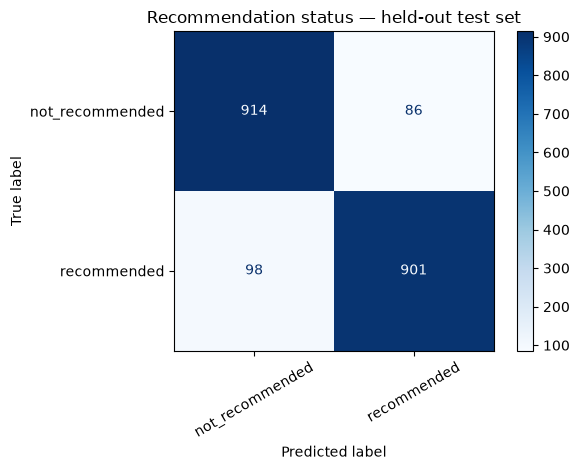

In [9]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Evaluate the model selected on training folds once on the reserved test set.
class_ids = list(LABEL_NAMES)
class_names = [LABEL_NAMES[class_id] for class_id in class_ids]
y_pred = best_pipeline.predict(X_test)

print("Held-out test classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=3,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=class_ids,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30,
)
plt.title("Recommendation status — held-out test set")
plt.tight_layout()
plt.show()


### Calibrate the selected TF-IDF model

Use the saved training folds for out-of-fold sigmoid calibration, then refit the selected pipeline on all training rows. The test set is used only for the report below. Calibration may change predicted labels, so compare accuracy and macro-F1 before and after it; inspect the Brier score and reliability diagram for `recommended`.


In [10]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

calibrated_pipeline = CalibratedClassifierCV(
    estimator=clone(best_pipeline),
    method="sigmoid",
    cv=cv,
    ensemble=False,
    n_jobs=N_JOBS,
)
# Calibration uses out-of-fold training scores; the reserved test rows stay untouched.
with parallel_config(backend="loky", inner_max_num_threads=1):
    calibrated_pipeline.fit(X_train, y_train)

print("Calibrated model:", type(best_pipeline.named_steps["model"]).__name__)
print("Classes:", calibrated_pipeline.classes_)


Calibrated model: LinearSVC
Classes: [0 1]


,model,test_accuracy,test_macro_f1
0,Selected TF-IDF (before calibration),0.907954,0.907950
1,Selected TF-IDF (sigmoid calibrated),0.906453,0.906453


Final calibrated test accuracy: 0.9064532266133066
Final calibrated test macro-F1: 0.9064528520502455
Calibrated Brier score (lower is better): 0.06802413264020442
Calibrated classification report:
                 precision    recall  f1-score   support

not_recommended      0.905     0.908     0.907      1000
    recommended      0.908     0.905     0.906       999

       accuracy                          0.906      1999
      macro avg      0.906     0.906     0.906      1999
   weighted avg      0.906     0.906     0.906      1999



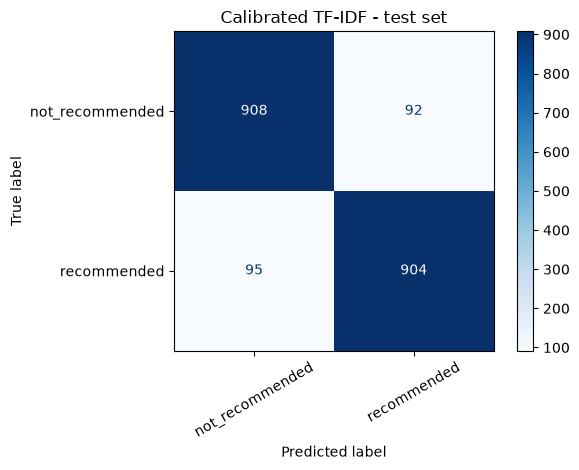

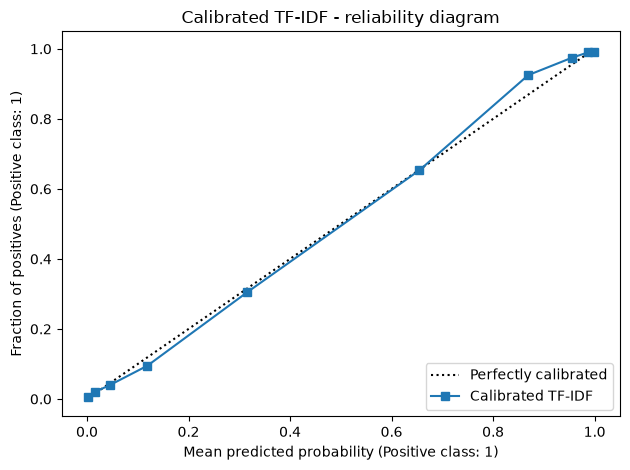

In [11]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss, accuracy_score, f1_score

calibrated_pred = calibrated_pipeline.predict(X_test)
positive_label = LABELS["recommended"]
positive_index = list(calibrated_pipeline.classes_).index(positive_label)
recommended_probability = calibrated_pipeline.predict_proba(X_test)[:, positive_index]

final_scores = pd.DataFrame([
    {
        "model": "Selected TF-IDF (before calibration)",
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_macro_f1": f1_score(y_test, y_pred, average="macro"),
    },
    {
        "model": "Selected TF-IDF (sigmoid calibrated)",
        "test_accuracy": accuracy_score(y_test, calibrated_pred),
        "test_macro_f1": f1_score(y_test, calibrated_pred, average="macro"),
    },
])
display(final_scores)
print("Final calibrated test accuracy:", final_scores.loc[1, "test_accuracy"])
print("Final calibrated test macro-F1:", final_scores.loc[1, "test_macro_f1"])
print("Calibrated Brier score (lower is better):", brier_score_loss(
    y_test, recommended_probability, pos_label=positive_label,
))
print("Calibrated classification report:")
print(classification_report(
    y_test, calibrated_pred,
    labels=list(LABEL_NAMES),
    target_names=[LABEL_NAMES[label] for label in LABEL_NAMES],
    digits=3,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test, calibrated_pred,
    labels=list(LABEL_NAMES),
    display_labels=[LABEL_NAMES[label] for label in LABEL_NAMES],
    cmap="Blues", values_format="d", xticks_rotation=30,
)
plt.title("Calibrated TF-IDF - test set")
plt.tight_layout()
plt.show()

CalibrationDisplay.from_predictions(
    y_test, recommended_probability,
    n_bins=10, strategy="quantile", pos_label=positive_label,
    name="Calibrated TF-IDF",
)
plt.title("Calibrated TF-IDF - reliability diagram")
plt.tight_layout()
plt.show()


### Save the calibrated TF-IDF pipeline

Save the calibrated vectorizer and classifier fitted on all training rows. This is the result of the TF-IDF experiment; the final comparison notebook will choose between model families and handle delivery to Django. The saved estimator supports `predict_proba`.


In [ ]:
import json
import joblib

output_dir = PROJECT_ROOT / "notebooks" / "recommendation detection" / "output models"
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / "tfidf_pipeline.joblib"
joblib.dump(calibrated_pipeline, model_path)
print(f"Saved calibrated TF-IDF model to {model_path}")

# Keep the training CV score and dataset identity with this artifact.
from hashlib import sha256
metrics = {
    "approach": "TF-IDF",
    "selected_model": type(best_pipeline.named_steps["model"]).__name__,
    "cv_macro_f1": float(grid.best_score_),
    "train_sha256": sha256(train_path.read_bytes()).hexdigest(),
    "test_sha256": sha256(test_path.read_bytes()).hexdigest(),
}
(output_dir / "tfidf_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
